# Deepfake Detection — Ablation Study
### Baseline MobileNetV2 → Attention-Enhanced CNN

**Course:** Deep Learning  
**Dataset:** FaceForensics++ C23 — 100k extracted faces  

This notebook implements Phase 1 of the ablation study:
1. **Baseline** — pretrained MobileNetV2 fine-tuned for binary classification
2. **Attention CNN** — channel-wise attention added on top of MobileNetV2 features

> See `Deepfake Research Extension.ipynb` for Phase 2: the Hybrid Spatial-Frequency model.


## 1. Environment Setup

In [1]:
import os

# Credentials are read from the environment. Never hard-code them in a notebook.
assert os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY"), "Set KAGGLE_USERNAME and KAGGLE_KEY in the environment first."

In [2]:
!kaggle datasets download -d gradientvoyager/faceforensics-c23-extracted-faces-100k

Dataset URL: https://www.kaggle.com/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k
License(s): CC-BY-NC-SA-4.0
100% 2.46G/2.46G [00:35<00:00, 74.2MB/s]



In [3]:
!unzip faceforensics-c23-extracted-faces-100k.zip -d dataset

Streaming output truncated to the last 5000 lines.
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f214.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f234.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f253.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f273.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f292.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f312.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f331.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f351.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f370.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f39.jpg  
  inflating: dataset/dataset_processed_split/val/NeuralTextures/789_753_f390.jpg  
  inflating: dataset/dataset_processe

In [4]:
data_dir = "/content/dataset/dataset_processed_split"

## 2. Data Loading & Preprocessing

### Transforms
- **Train:** `RandomHorizontalFlip`, `RandomRotation(±10°)`, `ColorJitter` + ImageNet normalisation
- **Val / Test:** Resize + ImageNet normalisation only

ImageNet normalisation (µ=[0.485,0.456,0.406], σ=[0.229,0.224,0.225]) is required for MobileNetV2 pretrained weights — without it, features are on a different scale than what the backbone was trained on.


In [6]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

data_dir = "/content/dataset/dataset_processed_split"

# Training: augmentation + ImageNet normalisation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Validation / Test: no augmentation
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(
    root=os.path.join(data_dir, "train"), transform=train_transform
)
val_dataset = datasets.ImageFolder(
    root=os.path.join(data_dir, "val"), transform=val_test_transform
)
test_dataset = datasets.ImageFolder(
    root=os.path.join(data_dir, "test"), transform=val_test_transform
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,
                          num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=32, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=32, num_workers=2, pin_memory=True)

print("Classes:", train_dataset.classes)
print("Training images:",   len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:",    len(test_dataset))

## 3. Binary Mapping & Balanced Sampling

We collapse the 7-class FaceForensics++ labels into binary (Real=0, Fake=1) and undersample the majority fake class to prevent class-imbalance bias in training.


In [7]:
from torch.utils.data import Dataset, DataLoader, Subset
import random

class BinaryDeepfakeDataset(Dataset):
    def __init__(self, imagefolder_dataset):
        self.dataset = imagefolder_dataset
        self.real_class_index = self.dataset.class_to_idx["Real"]

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]

        # Real = 0, Fake = 1
        binary_label = 0 if label == self.real_class_index else 1

        return image, binary_label


train_binary = BinaryDeepfakeDataset(train_dataset)
val_binary = BinaryDeepfakeDataset(val_dataset)
test_binary = BinaryDeepfakeDataset(test_dataset)

print("Binary mapping: Real = 0, Fake = 1")

Binary mapping: Real = 0, Fake = 1


In [8]:
real_indices = []
fake_indices = []

real_class_index = train_dataset.class_to_idx["Real"]

for idx, (_, label) in enumerate(train_dataset.samples):
    if label == real_class_index:
        real_indices.append(idx)
    else:
        fake_indices.append(idx)

print("Real training images:", len(real_indices))
print("Fake training images:", len(fake_indices))

random.seed(42)

sample_size = min(5000, len(real_indices), len(fake_indices))

selected_real = random.sample(real_indices, sample_size)
selected_fake = random.sample(fake_indices, sample_size)

balanced_indices = selected_real + selected_fake
random.shuffle(balanced_indices)

train_subset = Subset(train_binary, balanced_indices)

train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)

print("Balanced training subset size:", len(train_subset))

Real training images: 18391
Fake training images: 110086
Balanced training subset size: 10000


In [9]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 4. Baseline Model — MobileNetV2

Pretrained MobileNetV2 (ImageNet) with the final classifier replaced by a 2-neuron head. All backbone weights are fine-tuned (no layer freezing), allowing the model to adapt to deepfake artifacts.


In [10]:
import torch.nn as nn
from torchvision import models

# Load pretrained MobileNetV2
baseline_model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Replace final classifier for binary classification
baseline_model.classifier[1] = nn.Linear(baseline_model.last_channel, 2)

# Move model to GPU/CPU
baseline_model = baseline_model.to(device)

print(baseline_model)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 51.7MB/s]


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

## 5. Baseline — Training

In [11]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=0.0001)

print("Baseline model is ready.")

Baseline model is ready.


In [12]:
def train_model(model, train_loader, criterion, optimizer, epochs=3):
    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total

        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Loss: {running_loss / len(train_loader):.4f}")
        print(f"Accuracy: {accuracy:.2f}%")
        print("-" * 40)

In [13]:
train_model(
    baseline_model,
    train_loader,
    criterion,
    optimizer,
    epochs=3
)

Epoch [1/3]
Loss: 0.4811
Accuracy: 74.88%
----------------------------------------
Epoch [2/3]
Loss: 0.2151
Accuracy: 91.12%
----------------------------------------
Epoch [3/3]
Loss: 0.1013
Accuracy: 96.18%
----------------------------------------


## 6. Baseline — Evaluation

In [ ]:
def evaluate_model(model, data_loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            _, predicted = torch.max(model(images), 1)
            total   += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

In [16]:
val_loader_binary = DataLoader(val_binary, batch_size=32, shuffle=False)
test_loader_binary = DataLoader(test_binary, batch_size=32, shuffle=False)

val_accuracy = evaluate_model(baseline_model, val_loader_binary)
test_accuracy = evaluate_model(baseline_model, test_loader_binary)

print(f"Validation Accuracy: {val_accuracy:.2f}%")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Validation Accuracy: 87.52%
Test Accuracy: 88.59%


## 7. Attention-Enhanced CNN

Channel-wise attention (`1×1 Conv + Sigmoid`) is applied after MobileNetV2 feature extraction. The sigmoid gate re-weights each of the 1280 feature-map channels — effectively teaching the model *where* to look for manipulation artifacts rather than averaging all regions equally.


In [17]:
import torch
import torch.nn as nn
from torchvision import models

class AttentionModel(nn.Module):
    def __init__(self):
        super(AttentionModel, self).__init__()

        self.backbone = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )

        self.features = self.backbone.features

        self.attention = nn.Sequential(
            nn.Conv2d(1280, 1280, kernel_size=1),
            nn.Sigmoid()
        )

        self.pool = nn.AdaptiveAvgPool2d((1,1))

        self.classifier = nn.Linear(1280, 2)

    def forward(self, x):

        x = self.features(x)

        attention_map = self.attention(x)

        x = x * attention_map

        x = self.pool(x)

        x = torch.flatten(x, 1)

        x = self.classifier(x)

        return x

attention_model = AttentionModel().to(device)

print(attention_model)

AttentionModel(
  (backbone): MobileNetV2(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU6(inplace=True)
      )
      (1): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): ReLU6(inplace=True)
          )
          (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (2): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 96, kernel_siz

In [18]:
criterion = nn.CrossEntropyLoss()

optimizer_attention = torch.optim.Adam(
    attention_model.parameters(),
    lr=0.0001
)

print("Attention model ready.")

Attention model ready.


## 8. Attention Model — Training & Evaluation

In [19]:
train_model(
    attention_model,
    train_loader,
    criterion,
    optimizer_attention,
    epochs=3
)

Epoch [1/3]
Loss: 0.4369
Accuracy: 78.54%
----------------------------------------
Epoch [2/3]
Loss: 0.2016
Accuracy: 92.03%
----------------------------------------
Epoch [3/3]
Loss: 0.0971
Accuracy: 96.50%
----------------------------------------


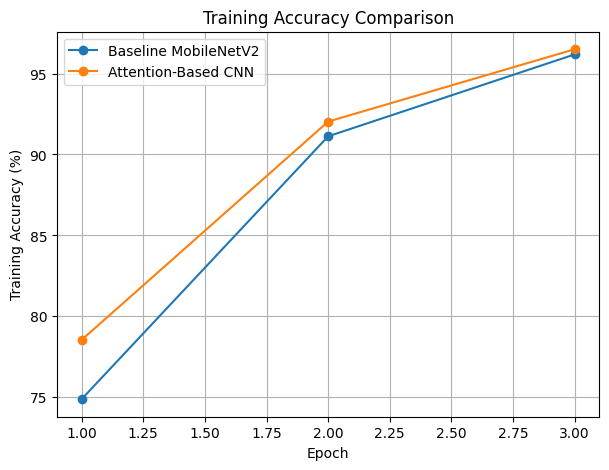

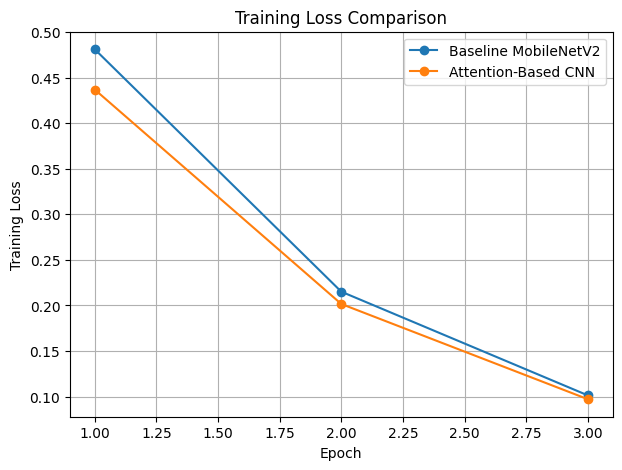

In [33]:
import matplotlib.pyplot as plt

baseline_acc = [74.88, 91.12, 96.18]
baseline_loss = [0.4811, 0.2151, 0.1013]

attention_acc = [78.54, 92.03, 96.50]
attention_loss = [0.4369, 0.2016, 0.0971]

epochs = [1, 2, 3]

plt.figure(figsize=(7,5))
plt.plot(epochs, baseline_acc, marker='o', label='Baseline MobileNetV2')
plt.plot(epochs, attention_acc, marker='o', label='Attention-Based CNN')
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy Comparison")
plt.legend()
plt.grid(True)
plt.savefig("training_accuracy_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs, baseline_loss, marker='o', label='Baseline MobileNetV2')
plt.plot(epochs, attention_loss, marker='o', label='Attention-Based CNN')
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.savefig("training_loss_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
val_accuracy_attention = evaluate_model(attention_model, val_loader_binary)
test_accuracy_attention = evaluate_model(attention_model, test_loader_binary)

print(f"Attention Validation Accuracy: {val_accuracy_attention:.2f}%")
print(f"Attention Test Accuracy: {test_accuracy_attention:.2f}%")

Attention Validation Accuracy: 90.78%
Attention Test Accuracy: 91.03%


## 9. Classification Report & Confusion Matrix

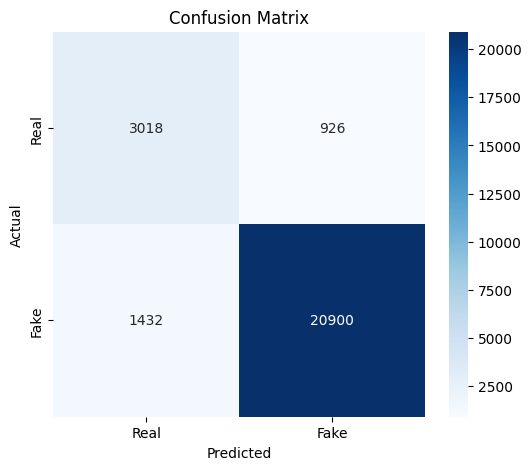

              precision    recall  f1-score   support

           0       0.68      0.77      0.72      3944
           1       0.96      0.94      0.95     22332

    accuracy                           0.91     26276
   macro avg       0.82      0.85      0.83     26276
weighted avg       0.92      0.91      0.91     26276



In [21]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

attention_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader_binary:

        images = images.to(device)

        outputs = attention_model(images)

        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Real','Fake'],
            yticklabels=['Real','Fake'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(all_labels, all_preds))

In [ ]:
from sklearn.metrics import roc_curve, auc
import torch.nn.functional as F

attention_model.eval()
roc_probs, roc_true = [], []

with torch.no_grad():
    for images, labels in test_loader_binary:
        probs = F.softmax(attention_model(images.to(device)), dim=1)[:, 1]
        roc_probs.extend(probs.cpu().numpy())
        roc_true.extend(labels.numpy())

fpr, tpr, _ = roc_curve(roc_true, roc_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, "darkorange", lw=2, label=f"ROC (AUC = {roc_auc:.4f})")
plt.plot([0,1],[0,1],"navy", lw=2, ls="--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Attention CNN")
plt.legend(loc="lower right"); plt.grid(True)
plt.savefig("roc_attention.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"AUC-ROC: {roc_auc:.4f}")

## 10. Grad-CAM Visualisation

Gradient-weighted Class Activation Mapping (Grad-CAM) highlights the spatial regions that most influenced the model's prediction. For deepfake images we expect activations around the face boundary, eyes, and mouth — typical blending artefact zones.


In [22]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 55.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44286 sha256=15f89a82730b7370cf24ea70b430a46e42fa014e5ff020e136d5565500a75620
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


In [23]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import matplotlib.pyplot as plt
import numpy as np
import torch

target_layers = [attention_model.features[-1]]

def show_gradcam(model, dataset, index):
    model.eval()

    image, label = dataset[index]
    input_tensor = image.unsqueeze(0).to(device)

    rgb_img = image.permute(1, 2, 0).numpy()
    rgb_img = np.clip(rgb_img, 0, 1)

    with torch.no_grad():
        output = model(input_tensor)
        pred = torch.argmax(output, dim=1).item()

    cam = GradCAM(model=model, target_layers=target_layers)
    grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(pred)])[0]

    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    plt.figure(figsize=(8,4))

    plt.subplot(1,2,1)
    plt.imshow(rgb_img)
    plt.title(f"Original | True: {'Fake' if label==1 else 'Real'}")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(visualization)
    plt.title(f"Grad-CAM | Predicted: {'Fake' if pred==1 else 'Real'}")
    plt.axis("off")

    plt.show()

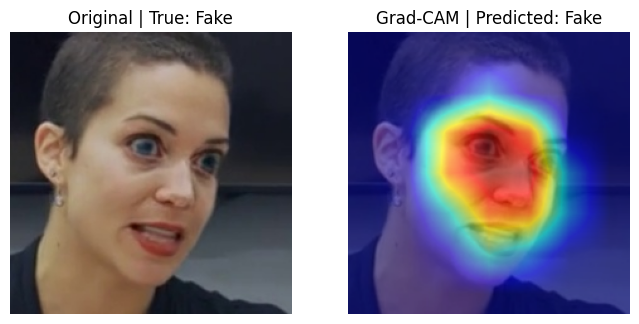

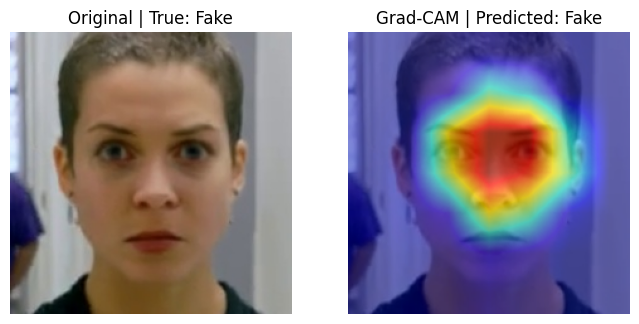

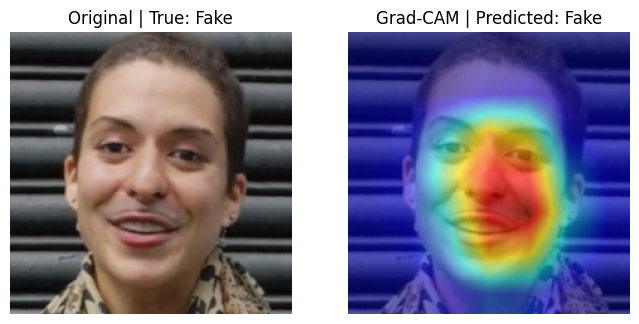

In [24]:
show_gradcam(attention_model, test_binary, 10)
show_gradcam(attention_model, test_binary, 100)
show_gradcam(attention_model, test_binary, 500)

## 11. Balanced Test Evaluation

Re-evaluate both models on a balanced test subset (3,000 real + 3,000 fake) to get an accuracy figure unaffected by class imbalance.


In [26]:
from torch.utils.data import Subset, DataLoader
import random

def create_balanced_subset(imagefolder_dataset, binary_dataset, max_per_class=3000):

    real_class_index = imagefolder_dataset.class_to_idx["Real"]

    real_indices = []
    fake_indices = []

    for idx, (_, label) in enumerate(imagefolder_dataset.samples):

        if label == real_class_index:
            real_indices.append(idx)

        else:
            fake_indices.append(idx)

    sample_size = min(max_per_class,
                      len(real_indices),
                      len(fake_indices))

    random.seed(42)

    selected_real = random.sample(real_indices, sample_size)
    selected_fake = random.sample(fake_indices, sample_size)

    balanced_indices = selected_real + selected_fake

    random.shuffle(balanced_indices)

    return Subset(binary_dataset, balanced_indices)

balanced_test_subset = create_balanced_subset(
    test_dataset,
    test_binary,
    max_per_class=3000
)

balanced_test_loader = DataLoader(
    balanced_test_subset,
    batch_size=32,
    shuffle=False
)

print("Balanced test size:", len(balanced_test_subset))

Balanced test size: 6000


In [27]:
baseline_balanced_test_acc = evaluate_model(
    baseline_model,
    balanced_test_loader
)

attention_balanced_test_acc = evaluate_model(
    attention_model,
    balanced_test_loader
)

print(f"Baseline Balanced Test Accuracy: {baseline_balanced_test_acc:.2f}%")
print(f"Attention Balanced Test Accuracy: {attention_balanced_test_acc:.2f}%")

Baseline Balanced Test Accuracy: 86.80%
Attention Balanced Test Accuracy: 85.10%


## 12. Sample Predictions

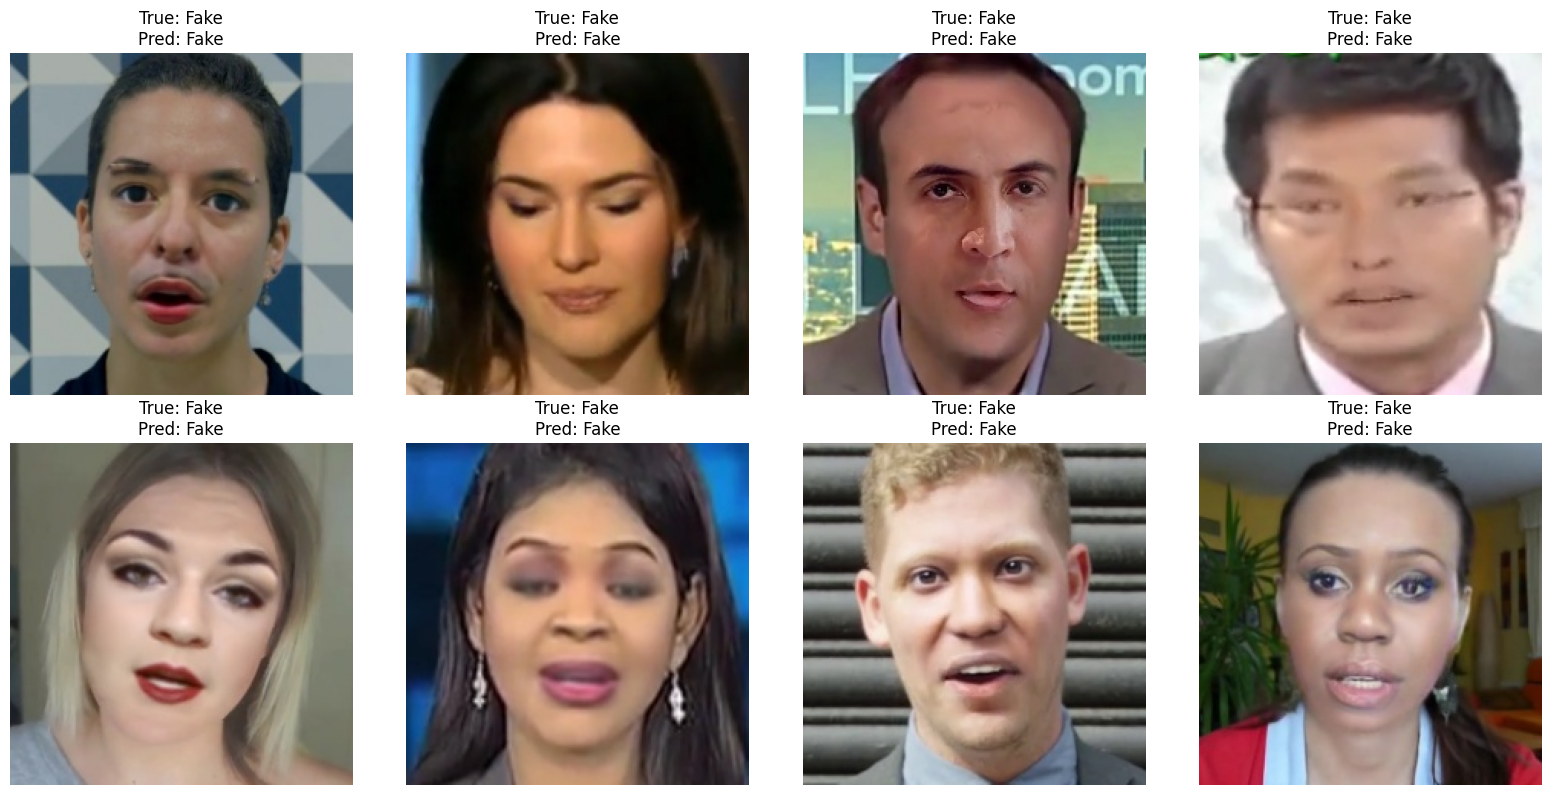

In [30]:
import torch
import matplotlib.pyplot as plt
import random

def show_sample_predictions(model, dataset, num_images=8):
    model.eval()
    indices = random.sample(range(len(dataset)), num_images)

    plt.figure(figsize=(16, 8))

    for i, idx in enumerate(indices):
        image, label = dataset[idx]
        input_image = image.unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_image)
            _, pred = torch.max(output, 1)

        true_label = "Fake" if label == 1 else "Real"
        pred_label = "Fake" if pred.item() == 1 else "Real"

        img = image.permute(1, 2, 0).cpu().numpy()

        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(f"True: {true_label}\nPred: {pred_label}")
        plt.axis("off")

    plt.tight_layout()
    plt.savefig("sample_predictions.png", dpi=300, bbox_inches="tight")
    plt.show()

show_sample_predictions(attention_model, test_binary, num_images=8)